# Number 1

===== DATASET DIMENSIONS =====
Rows: 4225958
Columns: 10

===== DATA TYPES =====
step                 int64
transactionType        str
amount             float64
initiator           string
oldBalInitiator    float64
newBalInitiator    float64
recipient           string
oldBalRecipient    float64
newBalRecipient    float64
isFraud              int64
dtype: object

===== MISSING VALUES =====
                 missing_count  missing_percent
step                         0              0.0
transactionType              0              0.0
amount                       0              0.0
initiator                    0              0.0
oldBalInitiator              0              0.0
newBalInitiator              0              0.0
recipient                    0              0.0
oldBalRecipient              0              0.0
newBalRecipient              0              0.0
isFraud                      0              0.0

===== EXACT DUPLICATES =====
Exact duplicate rows: 20

===== FRAUD LABEL AUDIT

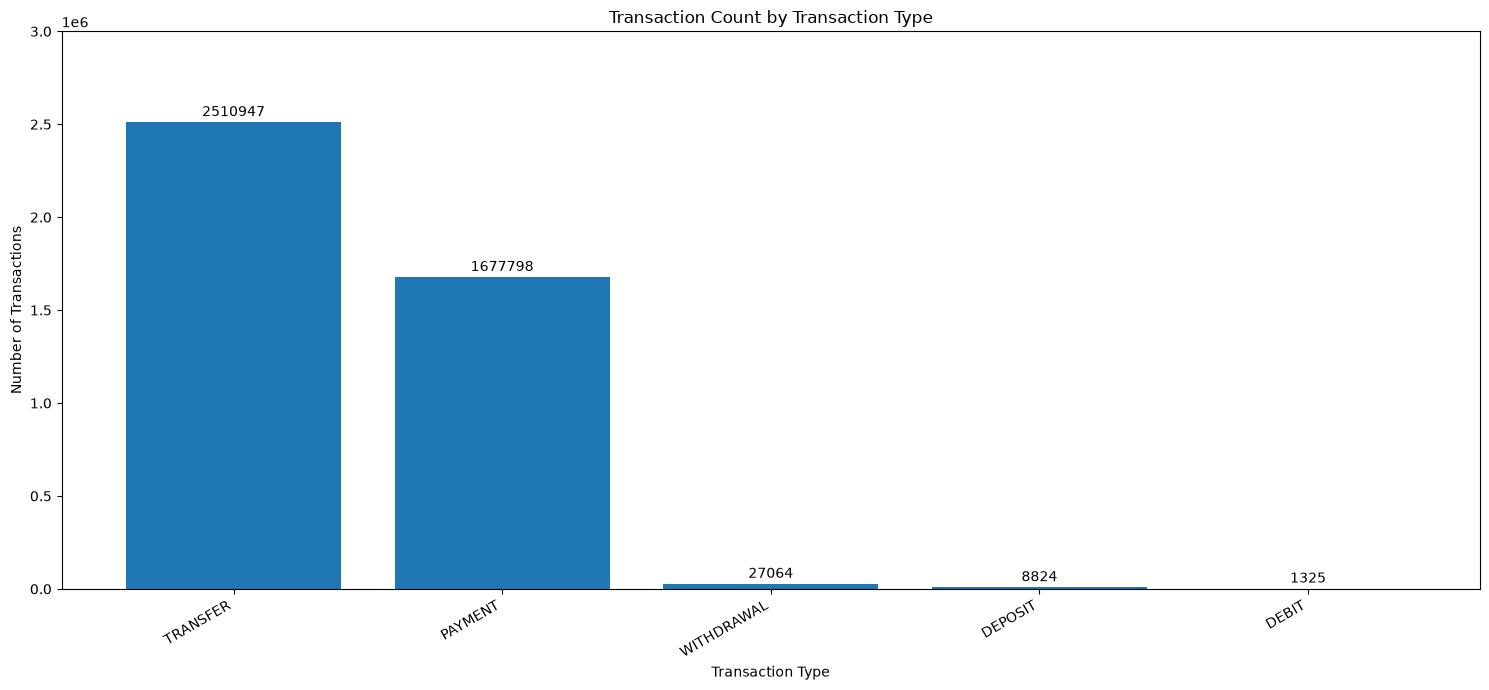

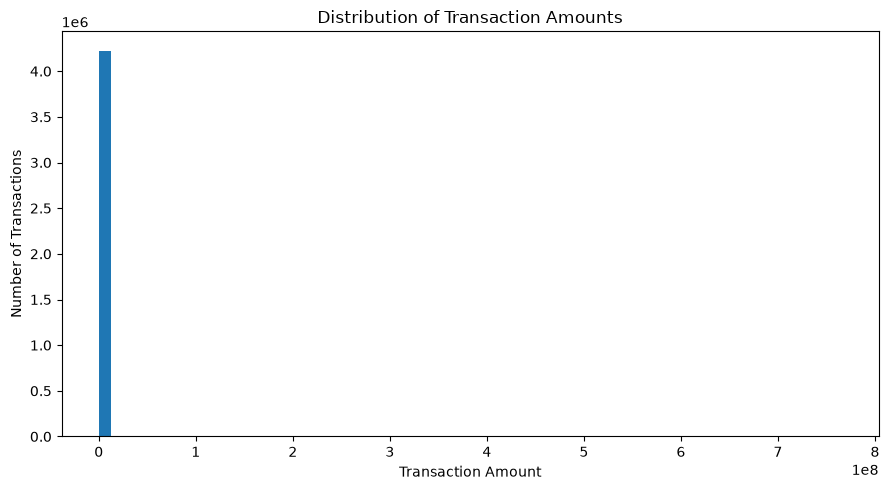

In [47]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "MoMTSim_20240722202413_1000_dataset.csv",
    dtype={"initiator": "string", "recipient": "string"}
)

# 1. Dataset dimensions
print("===== DATASET DIMENSIONS =====")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# 2. Data types
print("\n===== DATA TYPES =====")
print(df.dtypes)

# 3. Missing values
print("\n===== MISSING VALUES =====")
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
print(missing_report)

# 4. Exact duplicate rows
print("\n===== EXACT DUPLICATES =====")
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")
# print(df[df.duplicated(keep=False)].sort_values(by=list(df.columns))) Investigating duplicates

# 5. Invalid fraud labels
print("\n===== FRAUD LABEL AUDIT =====")
print("Observed labels:", df["isFraud"].value_counts(dropna=False).to_dict())

valid_labels = df["isFraud"].isin([0, 1])
valid_labels_transaction_type = df["transactionType"].isin(["PAYMENT", "TRANSFER", "DEPOSIT", "WITHDRAWAL", "DEBIT"])

print("INVALID LABELS")
invalid_label_count = (~valid_labels).sum()
invalid_label_count_transaction_type = (~valid_labels_transaction_type).sum()
print(f"Invalid or missing fraud labels: {invalid_label_count}")
print(f"Invalid or missing transactionType labels: {invalid_label_count_transaction_type}")

# 6. Negative balance investigation
print("\n===== NEGATIVE BALANCE AUDIT =====")
balance_columns = [
    "oldBalInitiator", "newBalInitiator", "amount",
]

for col in balance_columns:
    negative_count = (df[col] < 0).sum()
    print(f"{col}: {negative_count} negative values")

# Inspect transactions with any negative balance
negative_balances = df[(df[balance_columns] < 0).any(axis=1)]
print(f"\nTransactions with at least one negative balance: {len(negative_balances)}")
print(negative_balances.head(10))

# # 7. Check transaction types
# print("\n===== TRANSACTION TYPES =====")
# print(df["transactionType"].value_counts(dropna=False))

# # 8. Check transaction amounts
# print("\n===== AMOUNT AUDIT =====")
# print(df["amount"].describe())
# print("Negative amounts:", (df["amount"] < 0).sum())

# 9. Document the audit and apply only justified cleaning
# Keep the original data unchanged for now.

cleaned_df = df.drop(index=negative_balances.index).copy()
cleaned_df.drop_duplicates(inplace=True)

print("DIMENSIONS FOR ORIGINAL DATASET", df.shape)
print("DIMENSIONS FOR CLEANED DATASET", cleaned_df.shape)

# Do not remove negative balances or duplicates automatically.
# Investigate them first and document any justified changes.


# 2. Transaction-type summary
summary = df.groupby("transactionType").agg(
    count=("amount", "size"),
    total_amount=("amount", "sum"),
    median_amount=("amount", "median"),
    fraud_rate=("isFraud", "mean")
)

print(summary)

# Sort by transaction count
summary = summary.sort_values("count", ascending=False)

# Display monetary values to 2 decimal places and fraud rate as a percentage
summary["total_amount"] = summary["total_amount"].round(2)
summary["median_amount"] = summary["median_amount"].round(2)
summary["fraud_rate"] = (summary["fraud_rate"] * 100).round(2)

print("===== TRANSACTION-TYPE SUMMARY =====")
print(summary.to_string())

# 3. Plot transaction counts by type. X - Axis
counts = df["transactionType"].value_counts().sort_values(
    ascending=False
)

print("Debug MODE!!!")
print(counts.index)
print(counts.values)
print("Debug MODE!!!")

plt.figure(figsize=(15, 7))
bars = plt.bar(counts.index, counts.values)

plt.title("Transaction Count by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 3000000) 

# Label each bar with its count
plt.bar_label(bars, fmt="%.0f", padding=2)

plt.tight_layout()
plt.show()

# 4. Plot the distribution of transaction amounts
plt.figure(figsize=(9, 5))

plt.hist(df["amount"].dropna(), bins=60)
# plt.xlim(0, 400000)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()





## 1. a) Describe the simulation and the meaning of the fraud label.

MoMTSim is a tool that creates fake mobile money transactions that behave statistically like real transactions. It simulates normal activities, such as sending and withdrawing money, as well as fraudulent activities, such as account takeover and fraud using fake credentials.

The `isFraud` column tells us whether a transaction is fraudulent: 1 means fraudulent, while 0 means legitimate. It is the outcome we want our model to predict, not information the model should use to make its prediction.


## Data Quality Audit and Treatment

### 1. Dataset Dimensions
The dataset contains **4,225,958 rows and 10 columns**, representing a large collection of simulated mobile money transactions.

### 2. Data Types
The data types were examined to ensure they were appropriate for analysis. The `initiator` and `recipient` columns were loaded as strings because they represent account identifiers rather than numerical values. The remaining columns use suitable data types for transaction analysis.

The dataset contains 10 columns with the following data types:

| Column | Data type | Meaning |
|---|---|---|
| `step` | `int64` | Integer representing the simulation time step |
| `transactionType` | `str` | Type of transaction |
| `amount` | `float64` | Transaction amount |
| `initiator` | `string` | Account identifier of the sender |
| `oldBalInitiator` | `float64` | Sender's balance before the transaction |
| `newBalInitiator` | `float64` | Sender's balance after the transaction |
| `recipient` | `string` | Account identifier of the recipient |
| `oldBalRecipient` | `float64` | Recipient's balance before the transaction |
| `newBalRecipient` | `float64` | Recipient's balance after the transaction |
| `isFraud` | `int64` | Fraud label: 0 for legitimate transactions and 1 for fraudulent transactions |

The data types are generally appropriate for the dataset. The account identifiers are stored as strings because they identify accounts rather than represent numerical quantities. The transaction type is categorical, while the transaction amount and balance columns are numerical. The `step` column is an integer representing simulation time, and `isFraud` is an integer representing the outcome label. The fraud label will be excluded from the input features when training a predictive model.

### 3. Missing Values
No missing values were found in any of the 10 columns. Therefore, no treatment for missing data was necessary.

### 4. Exact Duplicate Rows
The audit found **zero exact duplicate rows**. Consequently, no records needed to be removed due to exact duplication.

### 5. Invalid Labels
The `isFraud` column contains two valid labels: `0` for legitimate transactions and `1` for fraudulent transactions. The dataset contains 1,992,840 legitimate transactions and 2,233,118 fraudulent transactions. No invalid or missing fraud labels were found. The `isFraud` column will be treated as the outcome variable rather than an input feature when building predictive models.

We also investigated the `transactionType` column and found no invalid labels.

### 6. Negative Balances
We investigated the negative balances in `oldBalInitiator`, `newBalInitiator`, `oldBalRecipient`, and `newBalRecipient` and found out that these four corresponding columns have **42574, 42627, 1, 0** respectively. For the `amount` column, we found no negative values as well.

### 7. Cleaning Decisions
The initial audit found no missing values or invalid fraud labels. No records were removed for these reasons. The account identifiers were retained as strings, and the original dataset was preserved for further investigation. Any decision to remove transactions with negative balances will be based on the findings of the investigation rather than an assumption that all negative balances are invalid.

Upon investigating and finding negative balances and duplicates we decided to drop the corresponding transactions, creating a new cleaned dataframe called **cleaned_df** which will be used for further analysis. The confirmation of the new cleaned dataset is evident through the reduced dimensions specifically the rows.


## 1. c)
### Transaction-Type Summary

| Transaction Type | Count | Total Amount | Median Amount | Fraud Rate (%) |
| :--- | :--- | :--- | :--- | :--- |
| **TRANSFER** | 2,510,947 | 8.565965e+10 | 14,966.15 | 88.94 |
| **PAYMENT** | 1,677,798 | 7.449373e+09 | 583.18 | 0.00 |
| **WITHDRAWAL** | 27,064 | 2.220242e+10 | 125,662.91 | 0.00 |
| **DEPOSIT** | 8,824 | 1.080205e+11 | 143,298.44 | 0.00 |
| **DEBIT** | 1,325 | 7.342520e+08 | 4,497.89 | 0.00 |

## Transaction Analysis: Skew, Class Imbalance, and Monetary Value

### 1. Distribution and Skew of Transaction Amounts

The histogram shows that the transaction amount distribution is **right-skewed**. Most transactions involve relatively small amounts, while a smaller number involve very large amounts, creating a long tail to the right. This means that a few unusually large transactions may significantly affect the mean transaction amount. Therefore, the median is useful for describing a typical transaction because it is less affected by extreme values.

### 2. Class Imbalance

The dataset contains 1,992,840 legitimate transactions from all the five classes combined (labelled `0`) and 2,233,118 fraudulent transactions (labelled `1`) from the transfer class alone. Legitimate transactions account for approximately 11.06% of the dataset, while fraudulent transactions account for approximately 88.94%.

This indicates **class imbalance**, as fraudulent transactions substantially outnumber legitimate transactions. 

### 3. Transaction Counts Versus Total Monetary Value

Transaction counts and total monetary value measure different aspects of transaction activity. Transaction counts show how frequently each transaction type occurs, while total monetary value represents the sum of the amounts involved in those transactions.

A transaction type may have a high count but a relatively low total monetary value if its individual transactions are generally small. Conversely, a less frequent transaction type may account for a higher total monetary value if its transactions involve larger amounts.


# Number 2

In [57]:
random_2k_sample = cleaned_df.sample(n=2000, random_state=42)

cols = ["amount", "oldBalInitiator", "newBalInitiator",
"oldBalRecipient", "newBalRecipient"]

X = random_2k_sample[cols].to_numpy(dtype=float)
n = X.shape[0]  # rows
print(pd.DataFrame(X[:3], columns=cols))
print(X.shape, X.T.shape, (X.T @ X).shape, (X @ X.T).shape)

     amount  oldBalInitiator  newBalInitiator  oldBalRecipient  \
0    628.92             0.00              0.0        143477.09   
1  16840.63         15281.30          15281.3             0.00   
2    558.88         19292.18          18733.3         94881.16   

   newBalRecipient  
0        143477.09  
1             0.00  
2         95440.04  
(2000, 5) (5, 2000) (5, 5) (2000, 2000)


## Part a
For X:<br>
There are 2000 rows and 5 columns

For X<sup>T</sup><br>
There are 5 rows and 2000 columns after transposing

For X<sup>T</sup>X<br>
To eliminate the rows
We reduce the

For XX<sup>T</sup><br>
To eliminate the columns
Since this is matrix 

Account IDs and transaction types are excluded from this numeric representation because they have no effect on the analysis of the dataset

## Part b


In [59]:
J = np.ones(n)
mu = X.T @ J / n

pandas_mean = random_2k_sample[cols].mean().to_numpy()
print("Our mean vector", mu)
print("Pandas means", pandas_mean)
print(np.allclose(mu, pandas_mean))

Our mean vector [   24936.72564    23662253.06812001 23640692.35505     1731151.293155
  1752222.8389    ]
Pandas means [   24936.72564  23662253.06812  23640692.35505   1731151.293155
  1752222.8389  ]
True


The total amount expressed as a dot product with 1

In [50]:
print(X[:, 0] @ J) 

49873451.28


Sanity check with pandas' sum

In [51]:
print(random_2k_sample["amount"].sum())

49873451.28


#### Why a column of X belongs to Rn , whereas xi belongs to R5
A column of \(X\) belongs to \(\mathbb{R}^n\) because it contains \(n\) real-valued entries, one for each observation in the dataset. In contrast, \(x_i\) belongs to \(\mathbb{R}^5\) because it represents a single observation described by five features: the transaction amount, the initiator's old and new balances, and the recipient's old and new balances.

Therefore, \(X \in \mathbb{R}^{n \times 5}\), where \(n\) represents the number of observations and \(5\) represents the number of features.

## Part c

In [52]:
# Standardize X
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1  # Avoid division by zero for constant features
Z = (X - mean) / std

# Choose two nonzero standardized transaction vectors
nonzero_indices = np.flatnonzero(np.linalg.norm(Z, axis=1) > 0)

i, j = nonzero_indices[:2]
u, v = Z[i], Z[j]

# Calculate vector properties
norm_u = np.linalg.norm(u)
norm_v = np.linalg.norm(v)
distance_standardized = np.linalg.norm(u - v)
dot_product = u @ v

cosine_similarity = dot_product / (norm_u * norm_v)
cosine_similarity = np.clip(cosine_similarity, -1, 1)

angle_degrees = np.degrees(np.arccos(cosine_similarity))

# Compare raw and standardized distances
distance_raw = np.linalg.norm(X[i] - X[j])

print("Transaction indices:", i, j)
print("||u||₂:", norm_u)
print("||v||₂:", norm_v)
print("||u - v||₂ (standardized):", distance_standardized)
print("uᵀv:", dot_product)
print("Cosine similarity:", cosine_similarity)
print("Angle (degrees):", angle_degrees)
print("Raw distance:", distance_raw)
print("Standardized distance:", distance_standardized)

Transaction indices: 0 1
||u||₂: 0.64516341780419
||v||₂: 0.5963245958584465
||u - v||₂ (standardized): 0.1945274969567694
uᵀv: 0.36699895611312866
Cosine similarity: 0.9539209184055452
Angle (degrees): 17.461094583423073
Raw distance: 204697.84197748714
Standardized distance: 0.1945274969567694


### Why similarity alone does not determine fraud
Similarity alone does not determine fraud because it only measures how similar two transactions are in terms of their feature vectors, not whether they are fraudulent. Two transactions may have similar amounts and account balances but different fraud labels. Likewise, a fraudulent transaction may be very different from other fraudulent transactions. Therefore, fraud detection requires considering other factors, such as transaction type, account behavior, and historical patterns, alongside similarity measures.

# Number 3

## Part a

In [53]:
# A step-by-type count matrix M from the full cleaned data

M = (
    cleaned_df.groupby(["step", "transactionType"])
      .size()
      .unstack(fill_value=0)
      .sort_index()
)

# Label the rows and columns
M.index.name = "Step"
M.columns.name = "Transaction Type"

print("Matrix shape:", M.shape)
print(M.head())

Matrix shape: (193, 5)
Transaction Type  DEBIT  DEPOSIT  PAYMENT  TRANSFER  WITHDRAWAL
Step                                                           
0                     0        0     8370     11179           0
1                     0       49     8337     10978           0
2                     0        7     8356     10943           0
3                     1       13     8316     11033           2
4                     0        0     8333     10968           0


### Step count vector M**I**<sub>5</sub>

In [54]:
# Create a vector of five ones
one_vector = np.ones(5)

# Calculate total transactions at each step
step_counts = M.to_numpy() @ one_vector

# Keep the step labels attached to the results
step_counts = pd.Series(
    step_counts,
    index=M.index,
    name="Total Transactions"
)

print(step_counts.head(193))

Step
0      19549.0
1      19364.0
2      19306.0
3      19365.0
4      19301.0
        ...   
188    24577.0
189    24110.0
190    24053.0
191    23436.0
192    22974.0
Name: Total Transactions, Length: 193, dtype: float64


In [55]:
print("Results agree:",
      np.allclose(step_counts, M.sum(axis=1)))

Results agree: True


### Plot transaction counts against step

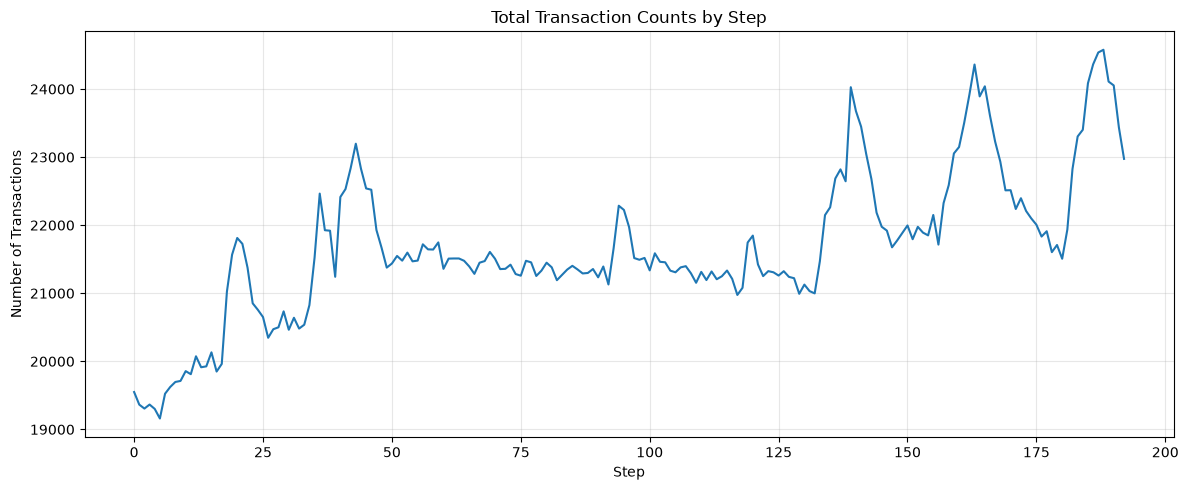

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(step_counts.index, step_counts.values)

plt.title("Total Transaction Counts by Step")
plt.xlabel("Step")
plt.ylabel("Number of Transactions")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Identify the three busiest steps

In [14]:
top_three = step_counts.nlargest(3)

print("Three busiest steps:")
print(top_three)

Three busiest steps:
Step
188    24577.0
187    24537.0
186    24362.0
Name: Total Transactions, dtype: float64


In [15]:
busiest_steps = top_three.rename_axis("Step").reset_index()
print(busiest_steps)

   Step  Total Transactions
0   188             24577.0
1   187             24537.0
2   186             24362.0


### The dominant transaction type at each busy step

In [16]:
dominant_types = M.loc[top_three.index].idxmax(axis=1)

results = pd.DataFrame({
    "Total Transactions": top_three,
    "Dominant Transaction Type": dominant_types,
    "Dominant Type Count": M.loc[top_three.index].max(axis=1)
})

print(results)

      Total Transactions Dominant Transaction Type  Dominant Type Count
Step                                                                   
188              24577.0                  TRANSFER                14519
187              24537.0                  TRANSFER                14402
186              24362.0                  TRANSFER                14455


## Part b

In [17]:
transfer_sample = random_2k_sample[
    random_2k_sample["transactionType"] == "TRANSFER"
].copy()

print("Sampled TRANSFER records:", len(transfer_sample))
print(transfer_sample["isFraud"].value_counts().sort_index())

Sampled TRANSFER records: 1186
isFraud
0     148
1    1038
Name: count, dtype: int64


### Constructing X<sub>T</sub>

In [18]:
cols = [
    "amount",
    "oldBalInitiator",
    "newBalInitiator",
    "oldBalRecipient",
    "newBalRecipient"
]

X_T = transfer_sample[cols].to_numpy()

print("X_T shape:", X_T.shape)

X_T shape: (1186, 5)


### Calculate the balance changes using matrix multiplication

In [19]:
B = np.array([
    [0, -1,  1,  0,  0],
    [0,  0,  0, -1,  1]
])

Y = X_T @ B.T

print("B shape:", B.shape)
print("B.T shape:", B.T.shape)
print("Y shape:", Y.shape)

print("First five balance changes:")
print(Y[:5])

B shape: (2, 5)
B.T shape: (5, 2)
Y shape: (1186, 2)
First five balance changes:
[[-9.2080000e+01  9.2080000e+01]
 [-3.1160000e+01  3.1170000e+01]
 [-4.7067231e+05  4.7067231e+05]
 [-2.8610000e+01  2.8600000e+01]
 [-9.7520000e+01  9.7520000e+01]]


### Verify the result by direct subtraction

In [20]:
delta_bI_direct = (
    transfer_sample["newBalInitiator"].to_numpy()
    - transfer_sample["oldBalInitiator"].to_numpy()
)

delta_bR_direct = (
    transfer_sample["newBalRecipient"].to_numpy()
    - transfer_sample["oldBalRecipient"].to_numpy()
)

print("Initiator matches:",
      np.allclose(Y[:, 0], delta_bI_direct))

print("Recipient matches:",
      np.allclose(Y[:, 1], delta_bR_direct))

Initiator matches: True
Recipient matches: True


### Calculate the residuals

In [21]:
# Transaction amounts from sampled TRANSFER records
a = transfer_sample["amount"].to_numpy()
# print("Sum entire amount column?", a)

# Balance-change residuals
rI = Y[:, 0] + a
rR = Y[:, 1] - a

print(rI, rR)

# Declare the monetary tolerance
tolerance = 0.01

print("Tolerance:", tolerance)
print("First 10 initiator residuals:", rI[:10])
print("First 10 recipient residuals:", rR[:10])

[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  0.00000000e+00
 -1.19325705e-09 -1.00000000e-02] [ 7.45075113e-11  9.99999993e-03  0.00000000e+00 ... -7.10542736e-14
 -1.00000000e-02  0.00000000e+00]
Tolerance: 0.01
First 10 initiator residuals: [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00 -9.99999993e-03
  0.00000000e+00  1.45519152e-11]
First 10 recipient residuals: [ 7.45075113e-11  9.99999993e-03  0.00000000e+00 -9.99999991e-03
  1.86304305e-11 -5.68434189e-14  1.00000001e-02  0.00000000e+00
  5.21538368e-10  0.00000000e+00]


### Identify residuals outside the tolerance

In [22]:
# Check each residual independently
initiator_mismatch = np.abs(rI) > tolerance
recipient_mismatch = np.abs(rR) > tolerance

print("Returning True or False?", initiator_mismatch)

# Overall mismatch: either balance fails the check
mismatch = initiator_mismatch | recipient_mismatch

print("Transfer records:", len(transfer_sample))
print("Initiator mismatches:", initiator_mismatch.sum())
print("Recipient mismatches:", recipient_mismatch.sum())
print("Overall mismatches:", mismatch.sum())
print("Overall mismatch proportion:", mismatch.mean())

Returning True or False? [False False False ... False False  True]
Transfer records: 1186
Initiator mismatches: 156
Recipient mismatches: 219
Overall mismatches: 249
Overall mismatch proportion: 0.20994940978077573


### Compare mismatch proportions by fraud label

In [23]:
# Attach mismatch results to the sampled TRANSFER records
transfer_sample["mismatch"] = mismatch

# Group by fraud label and calculate counts and proportions
comparison = transfer_sample.groupby("isFraud").agg(
    group_count=("mismatch", "size"),
    mismatch_count=("mismatch", "sum"),
    mismatch_proportion=("mismatch", "mean")
)

# Add percentages for easier interpretation
comparison["mismatch_percentage"] = (
    comparison["mismatch_proportion"] * 100
)

comparison.index = comparison.index.map({
    0: "Legitimate (0)",
    1: "Fraud (1)"
})

print(comparison)

                group_count  mismatch_count  mismatch_proportion  \
isFraud                                                            
Legitimate (0)          148              26             0.175676   
Fraud (1)              1038             223             0.214836   

                mismatch_percentage  
isFraud                              
Legitimate (0)            17.567568  
Fraud (1)                 21.483622  


The mismatch proportion for the fraudulent labels is greater than that of the legitimate labels. And their reported group counts are  **148** for legitimate and **1038** for fraudulent.

### Part C

Fraud count & rate

In [25]:
step_fraud = cleaned_df.groupby("step").agg(
    total_transactions=("isFraud", "size"),
    fraud_count=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

step_fraud["fraud_percentage"] = step_fraud["fraud_rate"] * 100

print(step_fraud.head(193))

      total_transactions  fraud_count  fraud_rate  fraud_percentage
step                                                               
0                  19549        11128    0.569236         56.923628
1                  19364        10916    0.563727         56.372650
2                  19306        10851    0.562053         56.205325
3                  19365        10924    0.564111         56.411051
4                  19301        10869    0.563131         56.313144
...                  ...          ...         ...               ...
188                24577        11727    0.477153         47.715344
189                24110        11728    0.486437         48.643716
190                24053        11806    0.490833         49.083274
191                23436        11673    0.498080         49.807988
192                22974        11769    0.512275         51.227475

[193 rows x 4 columns]


### Rates with step counts graph

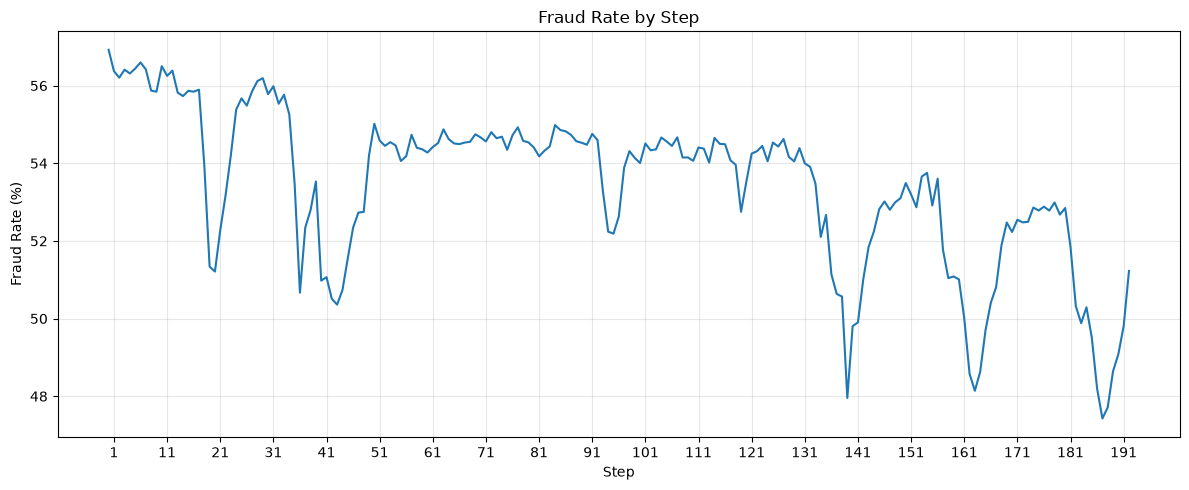

In [27]:
# plt.figure(figsize=(9, 5))

# plt.scatter(
#     step_fraud["total_transactions"],
#     step_fraud["fraud_rate"] * 100
# )

# plt.title("Transaction Counts vs Fraud Rates by Step")
# plt.xlabel("Step Transaction Count")
# plt.ylabel("Fraud Rate (%)")

# plt.tight_layout()
# plt.show()
plt.figure(figsize=(12, 5))

plt.plot(
    step_fraud.index,
    step_fraud["fraud_rate"] * 100
)

plt.title("Fraud Rate by Step")
plt.xlabel("Step")
plt.ylabel("Fraud Rate (%)")

plt.xticks(range(1, 194, 10))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

For the busy step (188), it is seen that it has a low fraud rate compared to a step with a high fraud rate that is evidenced with a low transaction count

### Comparison and explanation

Since step 188 has the highest transaction volume but a relatively low fraud rate, the provider should consider increasing customer support capacity during this period to manage demand and maintain service quality, while continuing routine fraud monitoring.

In contrast, step 1 has the highest fraud rate despite having one of the lowest transaction counts. This warrants further investigation to determine whether the high rate reflects a genuine suspicious pattern or is influenced by the small number of transactions. The provider should examine the fraudulent transactions and apply targeted monitoring where necessary.

Therefore, high transaction volume and high fraud rate require different responses: volume informs operational capacity planning, while fraud rates help identify periods for further investigation. Both fraud counts and transaction counts should be considered to avoid drawing misleading conclusions from percentages alone.

### Part d

#### Recommendations

1. Monitor fraud rate and transaction volume together by step, and investigate high-rate periods rather than staffing only according to transaction volume.

2. Prioritize review rules that combine transfer balance residuals with transaction amount and other context, while checking false positives

# Number 4

### Part a

In [39]:
# Count transactions at each step using the full cleaned data
ct = cleaned_df.groupby("step").size().sort_index()
# print(ct)
# Check the observed steps
steps = ct.index.to_numpy()
# print(steps)
step_diffs = np.diff(steps)
# print(step_diffs.size)
gaps = step_diffs[step_diffs > 1]
print(gaps)

[]


Upon investigation, there are no gaps to treat as zero-count periods.

In [42]:
# Align each step's count with the following observed step
    pairs = pd.DataFrame({
        "step_t": ct.index,
        "c_t": ct.to_numpy(),
        "step_next": ct.index.to_numpy()[1:].tolist() + [np.nan],
        "c_next": ct.shift(-1).to_numpy()
    })

# Keep only pairs whose steps differ by exactly one hour
pairs = pairs[
    (pairs["step_next"] - pairs["step_t"] == 1)
].copy()

print("Number of valid adjacent pairs:", len(pairs))
print(pairs.head(193))

Number of valid adjacent pairs: 192
     step_t    c_t  step_next   c_next
0         0  19549        1.0  19364.0
1         1  19364        2.0  19306.0
2         2  19306        3.0  19365.0
3         3  19365        4.0  19301.0
4         4  19301        5.0  19160.0
..      ...    ...        ...      ...
187     187  24537      188.0  24577.0
188     188  24577      189.0  24110.0
189     189  24110      190.0  24053.0
190     190  24053      191.0  23436.0
191     191  23436      192.0  22974.0

[192 rows x 4 columns]


### Creating the desing matrix and target vector

In [43]:
# Design matrix and target vector
X = np.column_stack([
    np.ones(len(pairs)),
    pairs["c_t"].to_numpy()
])

y = pairs["c_next"].to_numpy()

print("Design matrix X:", X.shape)
print("Target vector y:", y.shape)

Design matrix X: (192, 2)
Target vector y: (192,)


### Split chronologically: earliest 70% for training

In [44]:
n_pairs = len(pairs)
n_train = int(0.70 * n_pairs)

# Chronological split: no shuffling
X_train = X[:n_train]
y_train = y[:n_train]

X_test = X[n_train:]
y_test = y[n_train:]

train_pairs = pairs.iloc[:n_train]
test_pairs = pairs.iloc[n_train:]

print("Total pairs:", n_pairs)
print("Training pairs:", len(train_pairs))
print("Testing pairs:", len(test_pairs))

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print(
    "Split boundary:",
    f"last training pair: {train_pairs.iloc[-1]['step_t']} -> "
    f"{train_pairs.iloc[-1]['step_next']};",
    f"first testing pair: {test_pairs.iloc[0]['step_t']} -> "
    f"{test_pairs.iloc[0]['step_next']}"
)

Total pairs: 192
Training pairs: 134
Testing pairs: 58
X_train: (134, 2)
y_train: (134,)
X_test: (58, 2)
y_test: (58,)
Split boundary: last training pair: 133.0 -> 134.0; first testing pair: 134.0 -> 135.0


- Split boundary: last training pair: 133.0 -> 134.0; first testing pair: 134.0 -> 135.0
- matrix dimensions
  X_train: (134, 2)
  y_train: (134,)
  X_test: (58, 2)
  y_test: (58,)
- Reason for not randomly splitting: A random split is inapproriate because it can mix earlier and later periods between training and testing and make the evaluation less representative of forecasting future steps

### Part b

### Fit, Predict and evaluate

In [45]:
# Fit beta using the training data
        beta, residuals, rank, singular_values = np.linalg.lstsq(
            X_train, y_train, rcond=None
        )

beta0, beta1 = beta

print("Intercept (beta0):", beta0)
print("Slope (beta1):", beta1)

# Predict transaction counts for the test pairs
y_pred = X_test @ beta

# Persistence baseline: predict next hour = current hour
y_persistence = X_test[:, 1]

# Evaluation metrics
mae_model = np.mean(np.abs(y_test - y_pred))
rmse_model = np.sqrt(np.mean((y_test - y_pred) ** 2))

mae_persistence = np.mean(np.abs(y_test - y_persistence))
rmse_persistence = np.sqrt(
    np.mean((y_test - y_persistence) ** 2)
)

print("\nLinear model:")
print("MAE:", mae_model)
print("RMSE:", rmse_model)

print("\nPersistence baseline:")
print("MAE:", mae_persistence)
print("RMSE:", rmse_persistence)

Intercept (beta0): 1746.4838500937688
Slope (beta1): 0.9185037054508621

Linear model:
MAE: 295.4554092603902
RMSE: 388.8152921650437

Persistence baseline:
MAE: 298.2758620689655
RMSE: 378.5198487029035


### Part c

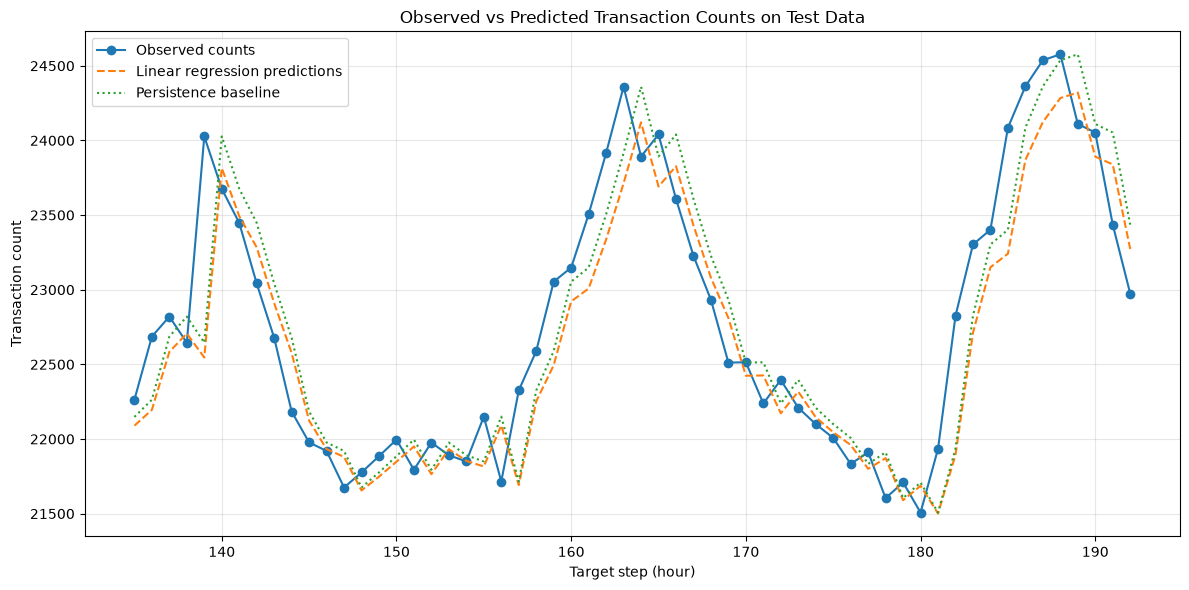

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    test_pairs["step_next"],
    y_test,
    label="Observed counts",
    marker="o"
)

plt.plot(
    test_pairs["step_next"],
    y_pred,
    label="Linear regression predictions",
    linestyle="--"
)

plt.plot(
    test_pairs["step_next"],
    y_persistence,
    label="Persistence baseline",
    linestyle=":"
)

plt.xlabel("Target step (hour)")
plt.ylabel("Transaction count")
plt.title("Observed vs Predicted Transaction Counts on Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Does the model improve on the baseline?
Not meaningfully. MAE improves by only about 0.9% (295.4554092603902 vs 298.2758620689655). The model is essentially persistence with mild mean reversion.

### How the errors affect staffing:
- Underprediction: If the actual count is higher than predicted, there may be too few staff available. This could cause longer queues, slower transaction processing, increased workloads, and poorer customer service.

- Overprediction: If the predicted count is higher than actual demand, more staff than necessary may be scheduled, increasing operating costs and leaving workers underutilized.

- Large errors: The higher RMSE of the linear model indicates that larger misses may be more pronounced than with the baseline. These errors could be particularly problematic during unusually busy or quiet hours.

### Discussion of findings
Both methods track the general level well but lag at turning points, since they only use the previous hour.
The linear model is not worth replacing persistence with.
Next step: add features like hour of day and the count from 24 hours earlier to capture the daily pattern, and re-evaluate on the same chronological split.